# mc_pm6_3 Escaped Asteroid Analysis
The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 

In [2]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm


In [3]:

pa_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mc_pm6_3/inputs/clone_assignments.h5')
ea_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mc_pm6_3/escaped_asteroids.h5')


In [4]:
print(pa_mvc3.sort_values(['sim_no', 'particle_number']).tail())

         ast_name                     particle_types  sim_no  particle_number
38088  2000 RV111  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043                9
57133       P_426  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043               10
19044      488807              [X, Y, Z, VX, VY, VZ]   19044                8
38089  2000 RV111              [X, Y, Z, VX, VY, VZ]   19044                9
57134       P_426              [X, Y, Z, VX, VY, VZ]   19044               10


In [5]:
ea_mvc3['ast_name'] = [x.replace(' ','') for x in ea_mvc3.ast_name]
ea_mvc3.set_index('ast_name', inplace=True)
ea_mvc3.describe()

,particle_number,parameter,parameter_value,integration_year
count,5093.000000,5093.000000,5093.000000,5.093000e+03
mean,9.260357,6.773807,2.431454,1.598360e+09
std,0.810716,0.766470,5.729688,1.768894e+09
min,8.000000,6.000000,0.000000,1.000000e+04
25%,9.000000,6.000000,0.341836,2.702136e+08
50%,9.000000,7.000000,0.416617,7.660057e+08
75%,10.000000,7.000000,0.711537,2.423673e+09
max,10.000000,8.000000,62.271265,6.283185e+09


In [6]:
print(f"Venus Ceres Mercurious escaped asteroids:{(ea_mvc3.index+ea_mvc3['vectors']).nunique()}")


Venus Ceres Mercurious escaped asteroids:2692


In [7]:
ea_mvc3.sort_values(by=['ast_name', 'vectors']).head(20)

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
104287,XYZVXVYVZ,02469,8,6,4.815804,5.774826e+09
104287,XYZVXVYVZ,02469,8,7,0.359443,5.133878e+09
104287,XYZVXVYVZ,02469,8,8,0.550722,5.723927e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,6,15.901978,2.952769e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,7,0.390441,2.910668e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,8,0.555398,2.930148e+09
104287,XcmYcpZcmVXcmVYcpVZcm,02450,8,7,0.342921,6.210293e+09
104287,XcmYcpZcmVXcmVYcpVZcm,02450,8,8,1.338067,6.222232e+09
104287,XcmYcpZcpVXcmVYcpVZcm,02442,8,6,5.842359,4.270483e+09


In [8]:
print(ea_mvc3.groupby(['parameter']).max())
print(ea_mvc3.groupby(['parameter']).min())

                         vectors sim_no  particle_number  parameter_value   
parameter                                                                   
6          XcpYcpZcpVXcpVYcpVZcp  18914               10        62.271265  \
7          XcpYcpZcpVXcpVYcpVZcp  18914               10         0.935531   
8          XcpYcpZcpVXcpVYcpVZcp  18914               10         2.021333   

           integration_year  
parameter                    
6              6.283185e+09  
7              6.263077e+09  
8              6.283185e+09  
             vectors sim_no  particle_number  parameter_value   
parameter                                                       
6          XYZVXVYVZ  00005                8         0.000000  \
7          XYZVXVYVZ  00005                8         0.340002   
8          XYZVXVYVZ  00005                8         0.550016   

           integration_year  
parameter                    
6              1.823303e+07  
7              1.266761e+06  
8              1.0

In [9]:
ea_mvc3.groupby(['ast_name']).head()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,6,4.118940,6.208498e+08
499395,XcpYcmZcpVXcpVYcmVZcp,00148,9,6,0.000000,6.214782e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,6,7.460342,5.435590e+08
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,7,0.429269,5.957146e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,7,0.448423,4.964305e+08
...,...,...,...,...,...,...
2006GO59,XcpYcpZcmVXcpVYcpVZcp,02543,10,6,0.000000,1.483078e+08
2012UL227,XcpYcpZcmVXcmVYcpVZcm,17888,10,6,0.000000,7.044244e+08
2012UL227,XcpYcmZcpVXcpVYcpVZcm,17892,10,6,0.000000,1.244293e+08


In [10]:
escapee_years = ea_mvc3.loc[ea_mvc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
escapee_years

,vectors,integration_year
ast_name,,
16794,XcpYcmZcpVXcpVYcmVZcp,9.881132e+07
499395,XcpYcmZcpVXcpVYcmVZcp,9.891133e+07
2002FL44,XcpYcmZcpVXcpVYcmVZcp,8.651010e+07
499395,XcmYcpZcmVXcmVYcpVZcp,1.802193e+08
2002FL44,XcmYcpZcmVXcmVYcpVZcp,2.360391e+07
...,...,...
2018VX15,XcpYcpZcmVXcpVYcmVZcp,1.290286e+07
2012UR215,XcpYcpZcmVXcpVYcmVZcp,1.390296e+07
467714,XcpYcpZcmVXcpVYcmVZcm,7.177722e+08


(array([877., 368., 198., 180., 117.,  77.,  90., 101.,  95.,  99.]),
 array([2.90187696e+06, 1.02611689e+08, 2.02321502e+08, 3.02031314e+08,
        4.01741126e+08, 5.01450938e+08, 6.01160751e+08, 7.00870563e+08,
        8.00580375e+08, 9.00290188e+08, 1.00000000e+09]),
 <BarContainer object of 10 artists>)

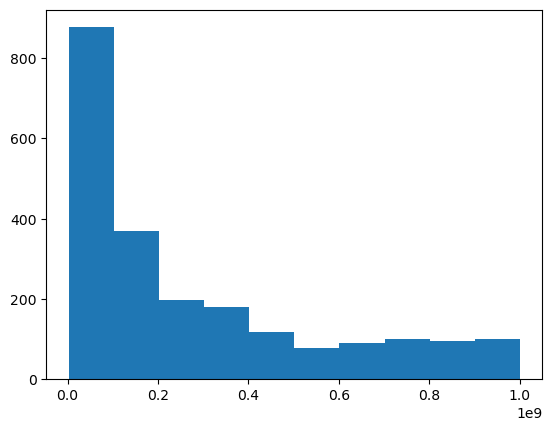

In [122]:
plt.hist(escapee_years.integration_year)

In [12]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])
mag_h = 17
p_v = 0.0387
luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.head())

  ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
0     1303     9.48  3.219248  0.121842  0.322276      1303  0.328133  \
1    11911    11.80  3.210027  0.132169  0.330567      1303  0.336904   
2    16794    13.45  3.229767  0.120773  0.321221      1303  0.327019   
3    17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
4    26558    13.15  3.194646  0.115763  0.319342      1303  0.325035   

        ideg       diam  
0  18.800624  85.836005  
1  19.303194  29.489642  
2  18.736782  13.793342  
3  18.836035  21.760531  
4  18.623137  15.836875  


In [13]:
luth_fam.set_index('ast_name')

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005
11911,11.80,3.210027,0.132169,0.330567,1303,0.336904,19.303194,29.489642
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
26558,13.15,3.194646,0.115763,0.319342,1303,0.325035,18.623137,15.836875
...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842


In [16]:
escaped_asts = ea_mvc3.index.unique()
len(escaped_asts)

104

In [17]:
luth_fam[luth_fam.ast_name.isin(escaped_asts)==True]

,ast_name,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
2,16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
3,17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
5,33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845
8,44492,13.69,3.220273,0.123425,0.324298,1303,0.330270,18.923050,12.350072
9,48296,13.44,3.224273,0.128330,0.326302,1303,0.332389,19.044475,13.857009
...,...,...,...,...,...,...,...,...,...
870,2013BG20,17.56,3.195066,0.141433,0.336048,1303,0.342718,19.636279,2.078115
871,2013BH34,17.37,3.198605,0.128226,0.327383,1303,0.333533,19.110011,2.268138
874,2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399
875,2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842


In [20]:
test_fam = luth_fam.copy()
test_fam = test_fam.set_index('ast_name')

In [121]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')

mean_escape['vec_count'] = ey_years.vectors.count()

escapee_years.sort_values('integration_year')


,vectors,integration_year
ast_name,,
2004UJ9,XcpYcpZcmVXcpVYcpVZcp,2.901877e+06
2004UJ9,XcmYcmZcpVXcmVYcpVZcm,5.702153e+06
533569,XcpYcmZcmVXcmVYcpVZcp,6.202202e+06
2005UM306,XcpYcmZcmVXcmVYcpVZcp,6.402221e+06
2004UJ9,XcpYcpZcmVXcpVYcpVZcm,6.802261e+06
...,...,...
2005CY40,XcmYcpZcmVXcpVYcpVZcm,9.940994e+08
2003UW410,XcmYcmZcmVXcmVYcmVZcp,9.968997e+08
2002GM31,XcmYcpZcpVXcpVYcmVZcp,9.971997e+08


In [116]:
counts, bins = np.histogram(mean_escape.vec_count, 3)

print(np.digitize(mean_escape.vec_count, bins))

[1 1 1 1 1 2 1 3 1 3 2 1 3 1 3 1 1 1 1 1 3 3 1 1 3 1 1 1 1 3 4 1 1 3 1 1 3
 1 2 2 1 2 4 3 3 1 1 1 1 3 3 1 3 1 2 3 2 3 1 1 1 1 1 2 1 2 1 2 1 1 2 1 1 1
 3 3 1 1 1 1 1 1 2 3 2 1 1 1 1 1 1 1 1 2 1 1 1 2 1 1]


In [23]:
test_fam['integration_year'] = mean_escape.integration_year
test_fam['vec_count'] = mean_escape.vec_count

test_fam = test_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
test_fam['graph_symbol'] = '.'
test_fam.loc[test_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(test_fam[test_fam['integration_year']!=0])

100

In [118]:
def flash_plot(ax, ast_data, y_column):
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            ax.scatter(data=m_fam, x='a_P',y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            colour_values = m_fam['integration_year']
            counts, bins = np.histogram(mean_escape.vec_count, 4)
            norm_vecs = (np.digitize(mean_escape.vec_count, bins)*35)
            print(m_fam.groupby('a_P'))
            pos = ax.scatter(data=m_fam, x='a_P',y=y_column, edgecolors='black', marker=graph_symbol, 
                    c=colour_values, cmap = cm_yr, s=norm_vecs , label='Escaped Candidates')
            cb = plt.colorbar(pos, label='Years from simulation start [$10^8 ~ yr$]', location='bottom')



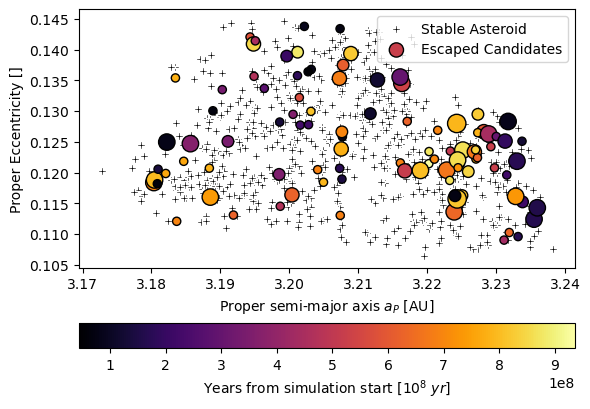

In [119]:
fig = plt.figure()
ax = plt.subplot(111)

flash_plot(ax, test_fam, 'e_P')

plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.legend()
plt.show()

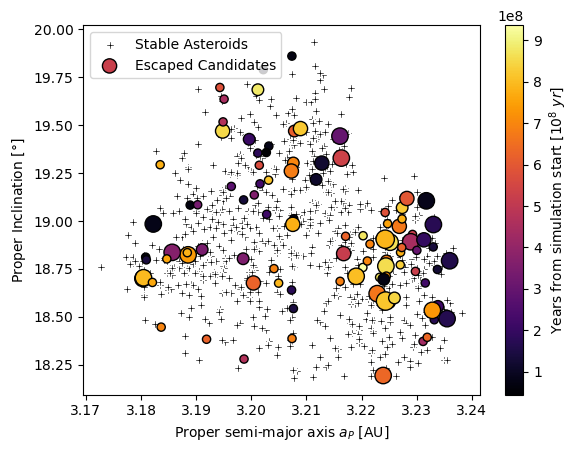

In [105]:
fig = plt.figure()
ax = plt.subplot(111)

flash_plot(ax, test_fam, 'ideg')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.legend()
plt.show()

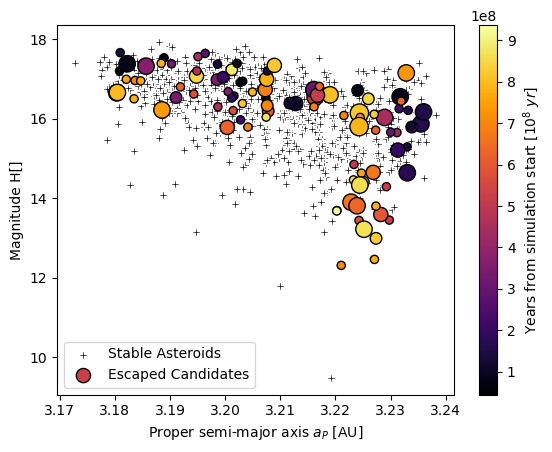

In [106]:
fig = plt.figure()
ax = plt.subplot(111)

flash_plot(ax, test_fam, 'abs_mag')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude H[]")
plt.legend()
plt.show()

In [28]:
print(luth_fam[luth_fam.ast_name.isin(escaped_asts)])


      ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
2        16794    13.45  3.229767  0.120773  0.321221      1303  0.327019  \
3        17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
5        33292    12.99  3.227360  0.129485  0.326713      1303  0.332824   
8        44492    13.69  3.220273  0.123425  0.324298      1303  0.330270   
9        48296    13.44  3.224273  0.128330  0.326302      1303  0.332389   
..         ...      ...       ...       ...       ...       ...       ...   
870   2013BG20    17.56  3.195066  0.141433  0.336048      1303  0.342718   
871   2013BH34    17.37  3.198605  0.128226  0.327383      1303  0.333533   
874  2013CE106    17.04  3.199622  0.138950  0.332601      1303  0.339060   
875   2013CG92    17.20  3.194881  0.135663  0.334094      1303  0.340644   
876  2013CP257    17.39  3.202177  0.143784  0.338581      1303  0.345408   

          ideg       diam  
2    18.736782  13.793342  
3    18.836035  21.